<a href="https://colab.research.google.com/github/FAB-V-V/Busca-minas/blob/main/Reglas_buscaminas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/0 MACC/2026 - 2/Lógica/0. Proyecto"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/0 MACC/2026 - 2/Lógica/0. Proyecto


# Reglas del Buscaminas en Python
**Lógica para Ciencias de la Computación — 2026-II**
Juan Camilo Lozano González y Fabiana Vargas Velasco

En este notebook implementamos las reglas del paper (Entrega 2 corregida) como strings en notación inorder, siguiendo el procedimiento del taller *Representación de situaciones*.

1. [Descriptor](#des)
2. [Conjuntos de índices](#conj)
3. [Regla R1](#r1)
4. [Regla R2](#r2)
5. [Regla R3](#r3)
6. [Regla R4](#r4)
7. [Regla R5](#r5)
8. [Regla Total y Visualización](#rtotal)

# Descriptor <a class="anchor" id="des"></a>

Usamos un único descriptor:

$N(x,y,k)$ es verdadera sii la casilla $(x,y)$ tiene el valor $k$,

donde $k\in\{0,\dots,8\}$ es el número que muestra la casilla y $k=9$ significa que la casilla contiene una mina.

In [ ]:
from Logica import *
from types import MethodType

Nx = 5          # filas
Ny = 5          # columnas
Nk = 10         # valores: 0..8 números, 9 mina
MINA = 9
X = list(range(Nx))
Y = list(range(Ny))

N = Descriptor([Nx, Ny, Nk])
print("Cantidad de átomos N:", N.rango[1] - N.rango[0])

Cantidad de átomos N: 250


Como en el taller, agregamos un método `escribir` para leer cada letra en español. Aquí distinguimos el caso de la mina ($k=9$):

In [ ]:
def escribir(self, literal):
    if '-' in literal:
        atomo = literal[1:]
        neg = ' no'
    else:
        atomo = literal
        neg = ''
    x, y, k = self.unravel(atomo)
    if k == MINA:
        return f"La casilla ({x},{y}){neg} tiene mina"
    else:
        return f"La casilla ({x},{y}){neg} muestra el {k}"

N.escribir = MethodType(escribir, N)

In [ ]:
atomo = N.ravel([0, 2, 9])
print("El caracter es", atomo)
print(N.escribir(atomo))
print(N.escribir('-' + N.ravel([4, 0, 0])))

El caracter es ǫ
La casilla (0,2) tiene mina
La casilla (4,0) no muestra el 0


# Conjuntos de índices <a class="anchor" id="conj"></a>

Tal como en la Sección IV-A del paper:

* $C$: las 25 casillas.
* $K(x,y)$: los **números** que puede mostrar la casilla. En las esquinas $\{0,1,2,3\}$; en las demás $\{0,1,2,3,4\}$. Observe que $9\notin K(x,y)$.

In [ ]:
C = [(x, y) for x in X for y in Y]

esquinas = [(0, 0), (0, Ny-1), (Nx-1, 0), (Nx-1, Ny-1)]

def K(x, y):
    if (x, y) in esquinas:
        return [0, 1, 2, 3]
    else:
        return [0, 1, 2, 3, 4]

print("Casillas:", len(C))
print("K(0,0) =", K(0, 0))
print("K(2,2) =", K(2, 2))

Casillas: 25
K(0,0) = [0, 1, 2, 3]
K(2,2) = [0, 1, 2, 3, 4]


# Regla R1 <a class="anchor" id="r1"></a>

**R1.** Toda casilla tiene algún valor: contiene una mina o muestra un número.

$$R_1\equiv\bigwedge_{(x,y)\in C}\ \bigvee_{k\in K(x,y)\cup\{9\}}N_{x,y,k}$$

Igual que en el taller, la construimos por pasos, de lo particular a lo general.

### Paso 1: una sola casilla

Para la casilla $(0,0)$, la fórmula dice "la casilla $(0,0)$ muestra el 0, o el 1, o el 2, o el 3, o tiene mina":

$$\bigvee_{k\in K(0,0)\cup\{9\}}N_{0,0,k}$$

In [ ]:
x = 0
y = 0
valores = K(x, y) + [MINA]      # K(x,y) ∪ {9}
print("Valores posibles:", valores)

lista_o = []
for k in valores:
    lista_o.append(N.ravel([x, y, k]))
formula_00 = Otoria(lista_o)
print(formula_00)

Valores posibles: [0, 1, 2, 3, 9]
((((ĀOę)OĲ)Oŋ)Oǡ)


In [ ]:
print(visualizar_formula(formula_00, N))

((((La casilla (0,0) muestra el 0 O La casilla (0,0) muestra el 1) O La casilla (0,0) muestra el 2) O La casilla (0,0) muestra el 3) O La casilla (0,0) tiene mina)


### Paso 2: todas las casillas

Ahora repetimos la O-toria para cada casilla de $C$ y unimos todas con una Y-toria:

In [ ]:
def regla1():
    lista_y = []
    for (x, y) in C:
        lista_o = []
        for k in K(x, y) + [MINA]:
            lista_o.append(N.ravel([x, y, k]))
        lista_y.append(Otoria(lista_o))
    return Ytoria(lista_y)

R1 = regla1()
print(R1)

((((((((((((((((((((((((((((ĀOę)OĲ)Oŋ)Oǡ)Y(((((ąOĞ)Oķ)OŐ)Oũ)OǦ))Y(((((ĊOģ)Oļ)Oŕ)OŮ)Oǫ))Y(((((ďOĨ)OŁ)OŚ)Oų)Oǰ))Y((((ĔOĭ)Oņ)Oş)Oǵ))Y(((((āOĚ)Oĳ)OŌ)Oť)OǢ))Y(((((ĆOğ)Oĸ)Oő)OŪ)Oǧ))Y(((((ċOĤ)OĽ)OŖ)Oů)OǬ))Y(((((ĐOĩ)Oł)Oś)OŴ)OǱ))Y(((((ĕOĮ)OŇ)OŠ)OŹ)OǶ))Y(((((ĂOě)OĴ)Oō)OŦ)Oǣ))Y(((((ćOĠ)OĹ)OŒ)Oū)OǨ))Y(((((ČOĥ)Oľ)Oŗ)OŰ)Oǭ))Y(((((đOĪ)OŃ)OŜ)Oŵ)Oǲ))Y(((((ĖOį)Oň)Oš)Oź)OǷ))Y(((((ăOĜ)Oĵ)OŎ)Oŧ)OǤ))Y(((((ĈOġ)Oĺ)Oœ)OŬ)Oǩ))Y(((((čOĦ)OĿ)OŘ)Oű)OǮ))Y(((((ĒOī)Oń)Oŝ)OŶ)Oǳ))Y(((((ėOİ)Oŉ)OŢ)OŻ)OǸ))Y((((ĄOĝ)OĶ)Oŏ)Oǥ))Y(((((ĉOĢ)OĻ)OŔ)Oŭ)OǪ))Y(((((ĎOħ)Oŀ)Oř)OŲ)Oǯ))Y(((((ēOĬ)OŅ)OŞ)Oŷ)OǴ))Y((((ĘOı)OŊ)Oţ)Oǹ))


Comprobamos que la cadena está bien escrita: `inorder_to_tree` debe convertirla en árbol sin error.

In [ ]:
A1 = inorder_to_tree(R1)
print("Letras en R1:", len(A1.letras()))     # 4*5 + 21*6 = 146
print(A1.ver(N)[:300], "...")

Letras en R1: 146
((((((((((((((((((((((((((((La casilla (0,0) muestra el 0 O La casilla (0,0) muestra el 1) O La casilla (0,0) muestra el 2) O La casilla (0,0) muestra el 3) O La casilla (0,0) tiene mina) Y (((((La casilla (0,1) muestra el 0 O La casilla (0,1) muestra el 1) O La casilla (0,1) muestra el 2) O La casi ...


### Verificación con interpretaciones

Una regla correcta debe ser **verdadera** en un tablero válido y **falsa** cuando se rompe lo que ella exige. Construimos a mano la interpretación del tablero de la Tabla II del paper:

In [ ]:
# Tablero de la Tabla II: valor de cada casilla (9 = mina)
tablero = [[1, 2, 9, 2, 1],
           [9, 3, 3, 9, 1],
           [2, 9, 2, 2, 2],
           [1, 2, 2, 2, 9],
           [0, 1, 9, 2, 1]]

def interpretacion(tablero):
    I = {}
    for (x, y) in C:
        for k in range(Nk):
            I[N.ravel([x, y, k])] = (tablero[x][y] == k)
    return I

I = interpretacion(tablero)
print("R1 en el tablero válido:", A1.valor(I))

R1 en el tablero válido: True


Ahora rompemos R1: dejamos la casilla $(4,0)$ **sin ningún valor**. R1 debe volverse falsa:

In [ ]:
I_roto = dict(I)
I_roto[N.ravel([4, 0, 0])] = False      # (4,0) ya no muestra el 0 y no tiene nada más
print("R1 con (4,0) vacía:", A1.valor(I_roto))

R1 con (4,0) vacía: False


Observe que R1 **no** detecta una casilla con dos valores (eso lo impiden R2 y R3, ver la Proposición 1 del paper). R1 solo exige *al menos* un valor:

In [ ]:
I_doble = dict(I)
I_doble[N.ravel([0, 0, 9])] = True      # (0,0) muestra 1 y además tiene mina
print("R1 con (0,0) doble:", A1.valor(I_doble))   # True: no es trabajo de R1

R1 con (0,0) doble: True


---
# Regla R2 <a class="anchor" id="r2"></a>

**R2.** El número que muestra una casilla es igual a la cantidad de minas en su vecindario.

$$R_2\equiv\bigwedge_{(x,y)\in C}\ \bigwedge_{\substack{k\in K(x,y)\\ k\neq 9}}\Big(N_{x,y,k}\rightarrow\mathrm{Ex}_k\big(V(x,y)\big)\Big)$$

con

$$\mathrm{Ex}_k(S)\equiv\bigvee_{\substack{T\subseteq S\\|T|=k}}\Big(\bigwedge_{(a,b)\in T}N_{a,b,9}\wedge\bigwedge_{(a,b)\in S\setminus T}\neg N_{a,b,9}\Big)$$

Sugerencia de pasos (como en el taller):

* **Paso 1.** Escribir una función `V(x, y)` que devuelva la lista de vecinas de $(x,y)$ dentro del tablero. Comprobar: `V(0,0)` tiene 3, `V(0,2)` tiene 5, `V(2,2)` tiene 8.
* **Paso 2.** Escribir `Ex(k, S)`. Para elegir los grupos $T$ de tamaño $k$ sirve `combinations(S, k)` de `itertools` (la misma que usa `Caballos.regla1` en `Problemas.py`). Cada $T$ da una Y-toria de letras `N.ravel([a,b,MINA])` para las casillas en $T$ y `'-' + N.ravel([a,b,MINA])` para las demás de $S$; luego una O-toria de todas.
  * Cuidado con $k=0$: `combinations(S, 0)` da un único grupo vacío, así que la Y-toria queda solo con negaciones ("ninguna vecina tiene mina"). Es correcto.
  * Comprobar con `visualizar_formula(Ex(1, V(0,0)), N)`: deben salir 3 disyuntos.
* **Paso 3.** Para una casilla y un $k$: `'(' + N.ravel([x,y,k]) + '>' + Ex(k, V(x,y)) + ')'`.
* **Paso 4.** Y-toria sobre todas las casillas y todos los $k\in K(x,y)$.
* **Verificación.** `inorder_to_tree(R2).valor(I)` debe dar `True` en el tablero de la Tabla II, y `False` si cambia un número (por ejemplo, poner que $(0,0)$ muestra 2 en vez de 1).

In [ ]:
from itertools import combinations

def V(x, y):
    lista_vecinas = []
    for i in range(-1, 2):
        for j in range(-1, 2):
            if (i, j) != (0, 0) and (x+i, y+j) in C:
                lista_vecinas.append((x+i, y+j))
    return lista_vecinas

In [ ]:
V(0,0)

[(0, 1), (1, 0), (1, 1)]

In [ ]:
def Ex(k, S):
    lista_o = []                              # un elemento por cada caso
    for T in combinations(S, k):              # ⋁ sobre los grupos T
        lista_y = []                          # caja nueva para este caso
        for (a, b) in S:                      # ⋀ sobre las casillas de S
            if (a, b) in T:
                lista_y.append(N.ravel([a, b, MINA]))
            else:
                lista_y.append('-' + N.ravel([a, b, MINA]))
        lista_o.append(Ytoria(lista_y))       # el caso completo
    return Otoria(lista_o)                    # caso A O caso B O caso C

In [ ]:
print(visualizar_formula(Ex(1, V(0, 0)), N))   # deben salir 3 casos


((((La casilla (0,1) tiene mina Y  no La casilla (1,0) tiene mina) Y  no La casilla (1,1) tiene mina) O (( no La casilla (0,1) tiene mina Y La casilla (1,0) tiene mina) Y  no La casilla (1,1) tiene mina)) O (( no La casilla (0,1) tiene mina Y  no La casilla (1,0) tiene mina) Y La casilla (1,1) tiene mina))


In [ ]:
def regla2():
    lista_y = []                                   # una implicación por (casilla, k)
    for (x, y) in C:                               # ⋀ sobre las casillas
        for k in K(x, y):                          # ⋀ sobre los números (sin el 9)
            implicacion = '(' + N.ravel([x, y, k]) + '>' + Ex(k, V(x, y)) + ')'
            lista_y.append(implicacion)
    return Ytoria(lista_y)

R2 = regla2()

In [ ]:
inorder_to_tree(R2).valor(I)

True

---
# Regla R3 <a class="anchor" id="r3"></a>

**R3.** Una casilla que contiene una mina no muestra ningún número.

$$R_3\equiv\bigwedge_{(x,y)\in C}\Big(N_{x,y,9}\rightarrow\neg\bigvee_{k\in K(x,y)}N_{x,y,k}\Big)$$

In [ ]:
def regla3():
    lista_y = []                                     # una implicación por casilla
    for (x, y) in C:                                 # ⋀ sobre las casillas
        lista_o = []                                 # caja nueva para esta casilla
        for k in K(x, y):                            # ⋁ sobre los números (sin el 9)
            lista_o.append(N.ravel([x, y, k]))
        mina = N.ravel([x, y, MINA])
        implicacion = '(' + mina + '>-' + Otoria(lista_o) + ')'
        lista_y.append(implicacion)
    return Ytoria(lista_y)

R3 = regla3()
A3 = inorder_to_tree(R3)
print("R3 en el tablero válido:", A3.valor(I))

R3 en el tablero válido: True


Ahora rompemos R3: hacemos que la casilla $(0,0)$ **tenga mina además del número 1 que ya mostraba**. R3 debe volverse falsa:

In [ ]:
print("R3 con (0,0) mostrando 1 y teniendo mina:", A3.valor(I_doble))

R3 con (0,0) mostrando 1 y teniendo mina: False


---
# Regla R4 <a class="anchor" id="r4"></a>

**R4.** El tablero contiene exactamente seis minas, distribuidas de modo que una fila contiene dos minas y cada una de las otras cuatro filas contiene exactamente una.

$$R_4\equiv\bigvee_{f=0}^{4}\Big(\mathrm{Ex}_2(F_f)\wedge\bigwedge_{f'\neq f}\mathrm{Ex}_1(F_{f'})\Big)$$


In [ ]:
def F(f):                                             # conjunto de filas F_f
    return [(f, y) for y in Y]                        # retorna las 5 casillas de una fila f

def regla4():
    lista_o = []                                      # ⋁ sobre las 5 filas (f = 0..4)
    for f in X:
        lista_y = [Ex(2, F(f))]                       # ⋀ la fila f tiene exactamente 2 minas
        for f_prima in X:
            if f_prima != f:
                lista_y.append(Ex(1, F(f_prima)))     # todas las demás filas tienen exactamente 1 mina
        lista_o.append(Ytoria(lista_y))
    return Otoria(lista_o)

R4 = regla4()
A4 = inorder_to_tree(R4)
print("R4 en el tablero válido:", A4.valor(I))

R4 en el tablero válido: True


Ahora rompemos R4: quitamos la mina de $(0,2)$ **para que la fila 0 quede sin minas**. R4 debe volverse falsa:

In [ ]:
I_sin_mina = dict(I)
I_sin_mina[N.ravel([0, 2, MINA])] = False
print("R4 con una mina menos en la fila 0:", A4.valor(I_sin_mina))

R4 con una mina menos en la fila 0: False


---
# Regla R5 <a class="anchor" id="r5"></a>

**R5.** Al menos una casilla del tablero muestra el número $0$.

$$R_5\equiv\bigvee_{(x,y)\in C}N_{x,y,0}$$

In [ ]:
def regla5():
    lista_o = [N.ravel([x, y, 0]) for (x, y) in C]    # lista con la proposición de que la casilla (x,y) muestre 0
    return Otoria(lista_o)                            # al menos una de las casillas muestra 0

R5 = regla5()
A5 = inorder_to_tree(R5)
print("R5 en el tablero válido:", A5.valor(I))

R5 en el tablero válido: True


Ahora rompemos R5: en nuestro tablero el único 0 está en $(4,0)$; **usamos I_roto donde $(4,0)$ no muestra 0**. R5 debe volverse falsa:

In [ ]:
print("R5 sin ningún 0 en el tablero:", A5.valor(I_roto))

R5 sin ningún 0 en el tablero: False


---
# Regla Total y Visualización <a class="anchor" id="rtotal"></a>

El modelo completo es la conjunción de las cinco reglas:
$$R \equiv R_1 \wedge R_2 \wedge R_3 \wedge R_4 \wedge R_5$$

Letras proposicionales en el modelo completo: 146
¿El tablero de la Tabla II satisface todo el modelo R?: True


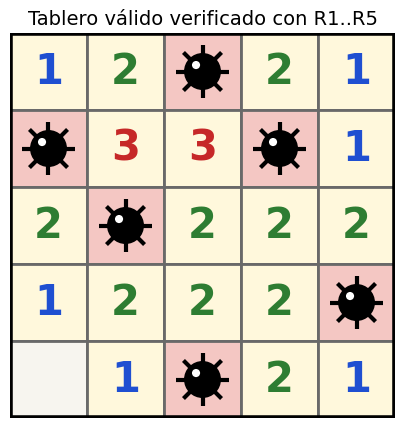

[]

In [ ]:
from visualizacion_buscaminas import dibujar_tablero

R_total = Ytoria([R1, R2, R3, R4, R5])
A_total = inorder_to_tree(R_total)

print("Letras proposicionales en el modelo completo:", len(A_total.letras()))
print("¿El tablero de la Tabla II satisface todo el modelo R?:", A_total.valor(I))

# Visualizamos la interpretación I usando el módulo de visualización
dibujar_tablero(I, titulo="Tablero válido verificado con R1..R5")